# Compare network predictions from TPS, TimeXNet, and Dynamics Bayesian Network - March 22, 2016

## Initializations

In [1]:
%pylab inline
import os
from collections import defaultdict
import pyupset as pyu
import pandas as pd

tps_dir = os.path.join('..','..','synthesis072614')
tps_file = os.path.join(tps_dir,'p-0.01_202dir_cytoscape_genes_092515.txt')
txn_file = os.path.join('..','..','TimeXNet','results','020916','net_4.5_0.0','lp_sol_4.5-0.0_nw.sif')
dbn_file = os.path.join('..','..','evaluation','2016-02-08','DBN','ppi-prior','max-indegree-2','network.tsv')

Populating the interactive namespace from numpy and matplotlib


## Helper functions to load the networks
Use : to separate proteins in an edge.  When loading a directed network, undirected edges are converted to a pair of directed edges.  When loading an undirected network, sort the protein names.  The node helper function takes the list of edges in a data frame, creates a set of the unique nodes in those edges, and returns a new data frame listing those nodes.

### TPS
Expect 413 undirected edges, 624 directed.  311 nodes.
- Activation, Inhibition, Unknown are directed edges
- None is an undirected edge

### TimeXNet
1073 total edges (178 directed) in original network.  Expect 1073 undirected, 1968 directed.  626 nodes.  TimeXNet node list has a bug, missing TXD11_HUMAN.
- pp indicates undirected edge in the input PPI network
- pd indicates directed edge in the input PPI network

### Dynamic Bayesian Network (DBN)
Use the PPI prior, max in-degree of 2 version of the network.  1139556 peptide-peptide interactions (1068^2-1068).  All peptide-peptide interactions are directed but still load an undirected version of the network in which the directionality is ignored and the proteins are sorted by name.  Store protein-protein edges by taking the max probability over all corresponding peptide-peptide edges.  There are initially 490909 = 701^2-(701-209) protein-protein edges because 209 of the 701 proteins have self-edges, likely due to multiple peptides mapping to the protein.  After filtering self-edges, there are 490700 = 701^2-701 directed protein-protein edges.  The undirected network has exactly half as many edges, 245350.  Ignore edge sign.

In [2]:
def load_tps_dir(tps_file):
    # Create a list of edges
    dir_edges = list()
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t Prot2 \t EdgeType
            parts = line.strip().split('\t')
            if parts[2] == 'None':
                # Add directed edge in both directions for an undirected prediction
                dir_edges.append('%s:%s' % (parts[0], parts[1]))
                dir_edges.append('%s:%s' % (parts[1], parts[0]))
            elif parts[2] == 'Activation' or parts[2] == 'Inhibition' or parts[2] == 'Unknown':
                dir_edges.append('%s:%s' % (parts[0], parts[1]))
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=dir_edges, columns=['Edges'])
    print 'Loaded %d directed edges from TPS network' % len(df)
    return df


def load_tps_undir(tps_file):
    # Create a list of edges
    undir_edges = list()
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t Prot2 \t EdgeType
            parts = line.strip().split('\t')
            if parts[2] == 'Activation' or parts[2] == 'Inhibition' or parts[2] == 'Unknown' or parts[2] == 'None':
                sorted_prots = sorted((parts[0], parts[1]))
                undir_edges.append('%s:%s' % (sorted_prots[0], sorted_prots[1]))
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=undir_edges, columns=['Edges'])
    print 'Loaded %d undirected edges from TPS network' % len(df)
    return df


def load_txn_dir(txn_file):
    # Create a list of edges
    dir_edges = list()
    
    with open(txn_file) as txn_f:
        for line in txn_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            if parts[1] == 'pp':
                # Add directed edge in both directions for an undirected prediction
                dir_edges.append('%s:%s' % (parts[0], parts[2]))
                dir_edges.append('%s:%s' % (parts[2], parts[0]))
            elif parts[1] == 'pd':
                dir_edges.append('%s:%s' % (parts[0], parts[2]))
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=dir_edges, columns=['Edges'])
    print 'Loaded %d directed edges from TimeXNet network' % len(df)
    return df


def load_txn_undir(txn_file):
    # Create a list of edges
    undir_edges = list()
    
    with open(txn_file) as txn_f:
        for line in txn_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            if parts[1] == 'pd' or parts[1] == 'pp':
                sorted_prots = sorted((parts[0], parts[2]))
                undir_edges.append('%s:%s' % (sorted_prots[0], sorted_prots[1]))
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=undir_edges, columns=['Edges'])
    print 'Loaded %d undirected edges from TimeXNet network' % len(df)
    return df


def load_dbn_dir(dbn_file):
    # Create a mapping of directed protein-protein edges to their max probability
    dir_edges = defaultdict(float)
    
    with open(dbn_file) as dbn_f:
        # Skip the header
        dbn_f.readline()
        for line in dbn_f:
            # protein 1 \t protein 2 \t probability \t sign \t peptide 1 \t peptide 2
            parts = line.strip().split('\t')
            # Ignore self-edges, which occur when a multiple peptides map to a protein
            if (not parts[0] == parts[1]):
                edge = '%s:%s' % (parts[0], parts[1])
                dir_edges[edge] = max(dir_edges[edge], float(parts[2]))
        
    # Create a data frame
    df = pd.DataFrame(data=dir_edges.items(), columns=['Edges', 'Probabilities'])
    print 'Loaded %d directed edges from Dynamic Bayesian Network' % len(df)
    return df


def load_dbn_undir(dbn_file):
    # Create a mapping of undirected protein-protein edges to their max probability
    # Strip the directionality of the edge
    undir_edges = defaultdict(float)
    
    with open(dbn_file) as dbn_f:
        # Skip the header
        dbn_f.readline()
        for line in dbn_f:
            # protein 1 \t protein 2 \t probability \t sign \t peptide 1 \t peptide 2
            parts = line.strip().split('\t')
            # Ignore self-edges, which occur when a multiple peptides map to a protein
            if (not parts[0] == parts[1]):
                sorted_prots = sorted((parts[0], parts[1]))
                edge = '%s:%s' % (sorted_prots[0], sorted_prots[1])
                undir_edges[edge] = max(undir_edges[edge], float(parts[2]))
        
    # Create a data frame
    df = pd.DataFrame(data=undir_edges.items(), columns=['Edges', 'Probabilities'])
    print 'Loaded %d undirected edges from Dynamic Bayesian Network' % len(df)
    return df


def extract_nodes(edge_df):
    node_set = set()
    for edge in edge_df['Edges']:
        parts = edge.split(':')
        node_set.add(parts[0])
        node_set.add(parts[1])
    
    # Create a new data frame
    return pd.DataFrame(data=list(node_set), columns=['Nodes'])

## Explore the DBN peptide-peptide network

In [3]:
dbn_df = pd.read_csv(dbn_file, sep='\t')
print 'Loaded %d DBN peptide-peptide interactions' % len(dbn_df)
dbn_df.head()

Loaded 1139556 DBN peptide-peptide interactions


,protein 1,protein 2,probability,sign,peptide 1,peptide 2
0,MEP50_HUMAN,Q96SA0_HUMAN,0.000456,1,-.n[305.21]MRK[432.30]ET[181.01]PPPLVPPAAR.E,-.n[305.21]MSTTAGY[243.03]LARR.A
1,MEP50_HUMAN,OTUL_HUMAN,0.000541,1,-.n[305.21]MRK[432.30]ET[181.01]PPPLVPPAAR.E,K.n[305.21]AAASGQPRPEMQC[160.03]PAEHEEDMY[243....
2,MEP50_HUMAN,Z512B_HUMAN,0.001765,1,-.n[305.21]MRK[432.30]ET[181.01]PPPLVPPAAR.E,K.n[305.21]AAGPAS[167.00]PPEEDPER.T
3,MEP50_HUMAN,DDX46_HUMAN,0.000558,1,-.n[305.21]MRK[432.30]ET[181.01]PPPLVPPAAR.E,K.n[305.21]AALGLQDS[167.00]DDEDAAVDIDEQIESMFNS...
4,MEP50_HUMAN,CCD43_HUMAN,0.000426,1,-.n[305.21]MRK[432.30]ET[181.01]PPPLVPPAAR.E,K.n[305.21]AALLAQYADVT[181.01]DEEDEADEK[432.30].D


## Plot the DBN peptide-peptide edge probability distribution
Want to choose thresholds to test in the network comparison below

113957 edges with probability >= 0.003404 (top 10%)
284891 edges with probability >= 0.002164 (top 25%)

0 edges with probability >= 0.100000
12 edges with probability >= 0.050000
378 edges with probability >= 0.025000
7944 edges with probability >= 0.010000
826810 edges with probability >= 0.001000


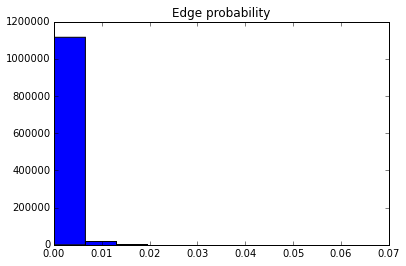

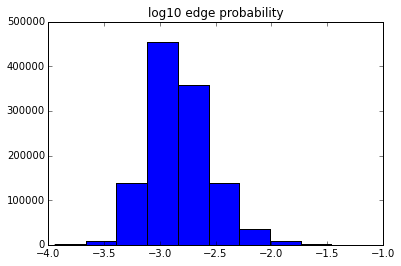

In [4]:
# Probability thresholds to get the top 10% and 25% of peptide-peptide edges
# Use the 90th and 75th percentile because we want edges with probability larger than the threshold
dbn_10p = np.percentile(dbn_df['probability'], 90)
dbn_25p = np.percentile(dbn_df['probability'], 75)

print '%d edges with probability >= %f (top 10%%)' % (sum(dbn_df['probability'] >= dbn_10p), dbn_10p)
print '%d edges with probability >= %f (top 25%%)\n' % (sum(dbn_df['probability'] >= dbn_25p), dbn_25p)

for thresh in [0.1, 0.05, 0.025, 0.01, 0.001]:
    print '%d edges with probability >= %f' % (sum(dbn_df['probability'] >= thresh), thresh)

hist(dbn_df['probability']);
title('Edge probability');

figure();
hist(log10(dbn_df['probability']));
title('log10 edge probability');

## Check for validated edges in TimeXNet network
Use the directed version to see if the edge exists as a directed or undirected edge, even though TimeXNet obtained the directions from the input data and doesn't predict directionality.

In [5]:
# Western blot-validated edges
edges = [('AKT1_HUMAN', 'ZYX_HUMAN'),
        ('ABL2_HUMAN', 'CRK_HUMAN'),
        ('MK01_HUMAN', 'AT1A1_HUMAN')]

# Load TimeXNet network
txn_dir_df = load_txn_dir(txn_file)

for e in edges:
    edge = '%s:%s' % (e[0], e[1])
    # Need to use series.values because in series will check the index of the series, not the values
    print '%s\t%s' % (edge, edge in txn_dir_df['Edges'].values)
    edge = '%s:%s' % (e[1], e[0])
    print '%s\t%s' % (edge, edge in txn_dir_df['Edges'].values)

Loaded 1968 directed edges from TimeXNet network
AKT1_HUMAN:ZYX_HUMAN	True
ZYX_HUMAN:AKT1_HUMAN	False
ABL2_HUMAN:CRK_HUMAN	False
CRK_HUMAN:ABL2_HUMAN	False
MK01_HUMAN:AT1A1_HUMAN	False
AT1A1_HUMAN:MK01_HUMAN	False


## Load the TPS, TimeXNet, and DBN networks

In [6]:
tps_undir_df = load_tps_undir(tps_file)
tps_dir_df = load_tps_dir(tps_file)
tps_node_df = extract_nodes(tps_undir_df)

txn_undir_df = load_txn_undir(txn_file)
txn_dir_df = load_txn_dir(txn_file)
txn_node_df = extract_nodes(txn_undir_df)

# Don't load the DBN nodes, they have to be computed after thresholding edges
dbn_undir_df = load_dbn_undir(dbn_file)
dbn_dir_df = load_dbn_dir(dbn_file)

Loaded 413 undirected edges from TPS network
Loaded 624 directed edges from TPS network
Loaded 1073 undirected edges from TimeXNet network
Loaded 1968 directed edges from TimeXNet network
Loaded 245350 undirected edges from Dynamic Bayesian Network
Loaded 490700 directed edges from Dynamic Bayesian Network


## Helper function to visualize the intersections
Threshold the DBN at the desired edge probability threshold and plot directed edge, undirected edge, and node intersections.  Relies on the global variables that contain the loaded networks.

In [7]:
 def visualize_intersections(thresh):
    print 'Generating figures for DBN edges with probability >= %f' % thresh

    # Threshold the DBN and identify the nodes
    dbn_dir_thresh_df = dbn_dir_df[dbn_dir_df['Probabilities'] >= thresh]
    dbn_undir_thresh_df = dbn_undir_df[dbn_undir_df['Probabilities'] >= thresh]
    
    # Don't need both sets of nodes, but do so any way to check correctness
    dbn_dir_nodes_df = extract_nodes(dbn_dir_thresh_df)
    dbn_undir_nodes_df = extract_nodes(dbn_undir_thresh_df)  

    assert set(dbn_dir_nodes_df['Nodes']) == set(dbn_undir_nodes_df['Nodes'])

    pyu.plot({'TPS directed':tps_dir_df, 'TimeXNet directed':txn_dir_df, 'DBN directed':dbn_dir_thresh_df});
    title('Directed edge intersections');
    
    pyu.plot({'TPS undirected':tps_undir_df, 'TimeXNet undirected':txn_undir_df, 'DBN undirected':dbn_undir_thresh_df});
    title('Undirected edge intersections');
    
    pyu.plot({'TPS nodes':tps_node_df, 'TimeXNet nodes':txn_node_df, 'DBN nodes':dbn_undir_nodes_df});
    title('Node intersections');

## Visualize the intersection between the TPS, TimeXNet, and DBN networks
Three types of sets to compare:
- Directed edges
- Undirected edges (all directed edges are stripped of their edge sign)
- Nodes

For the DBN, use various edge probability thresholds and only assess protein-protein edges with probability >= the threshold.  Use thresholds = [0.05, 0.04, 0.03, 0.02, 0.01, dbn_10p, dbn_25p], where the last two are for the top 10% and 25% of peptide-peptide edges.

Generating figures for DBN edges with probability >= 0.050000


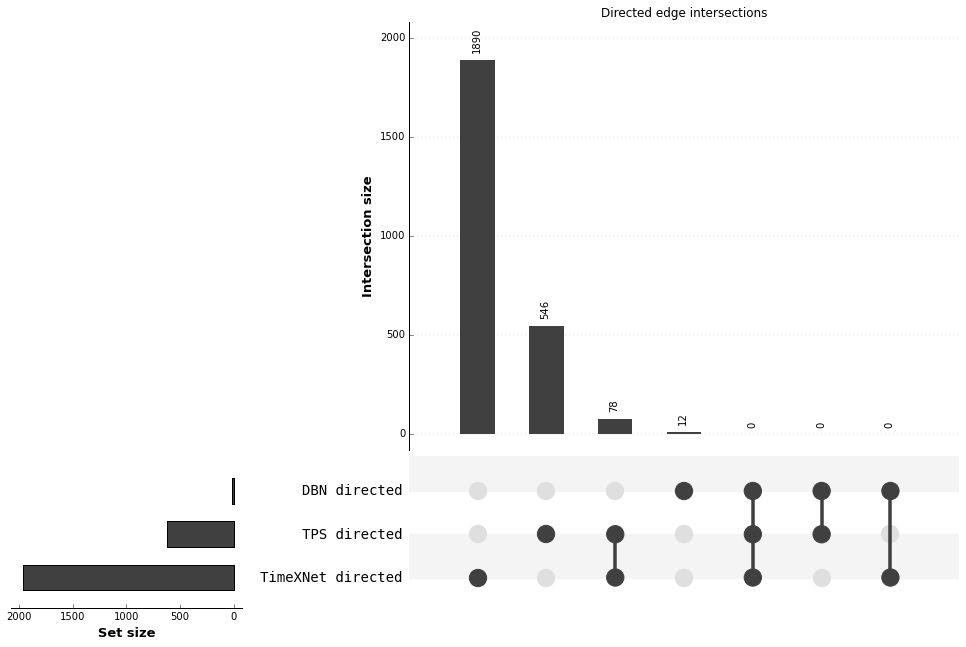

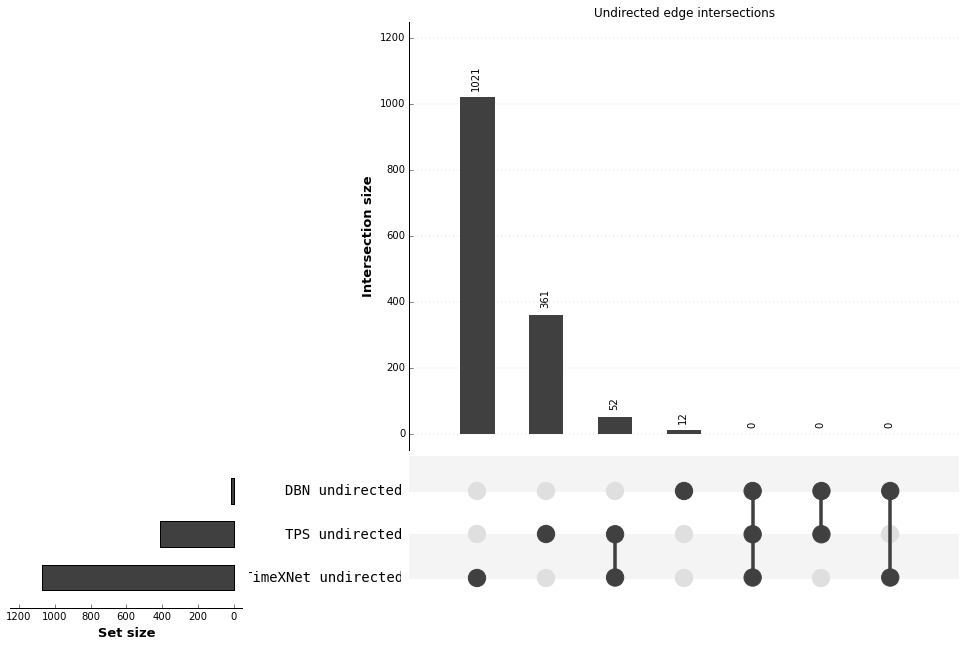

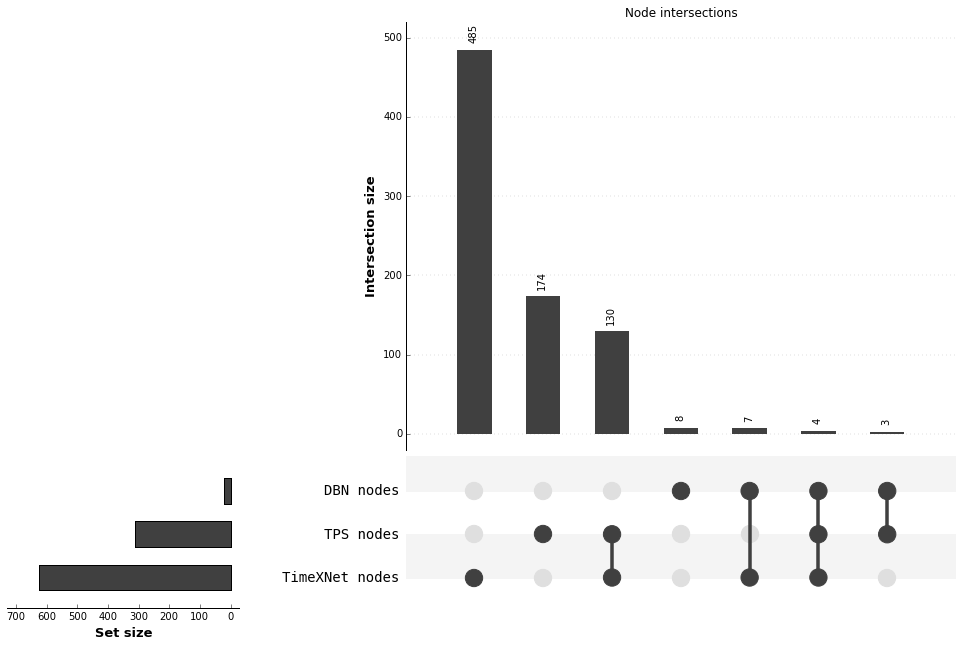

In [8]:
visualize_intersections(0.05)

Generating figures for DBN edges with probability >= 0.040000


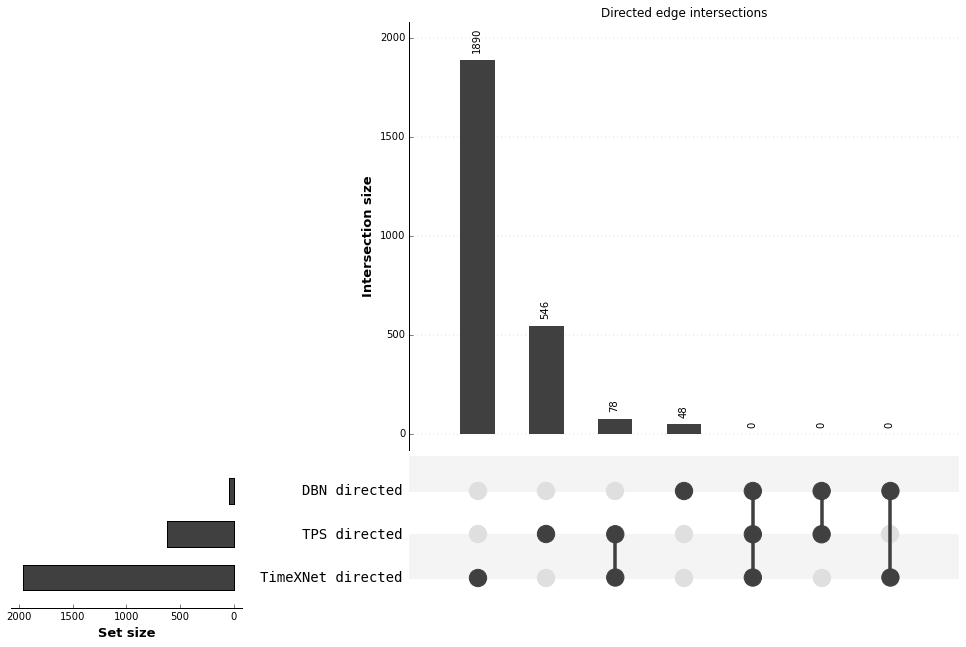

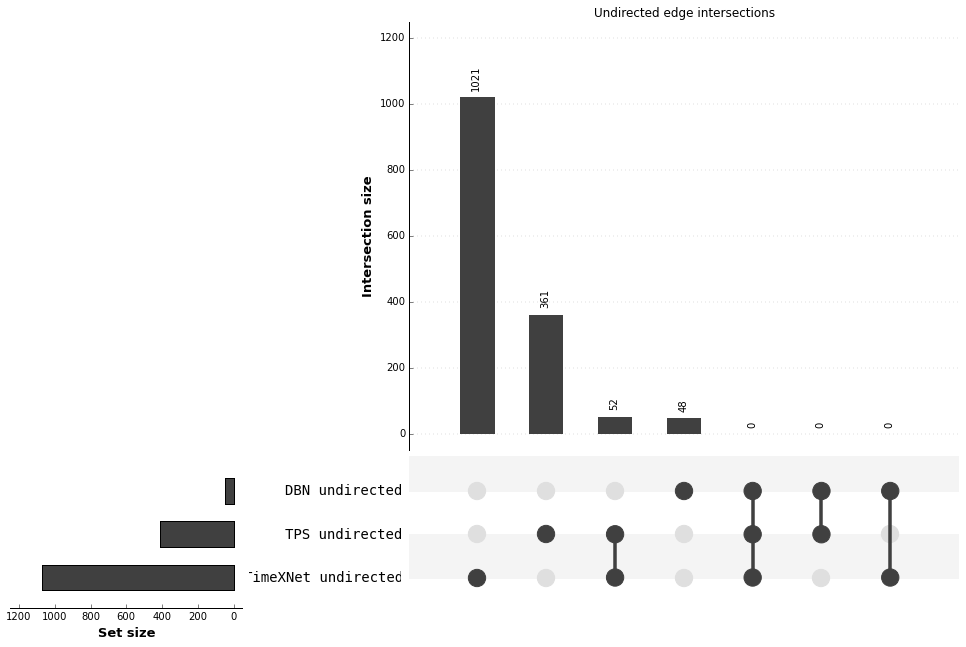

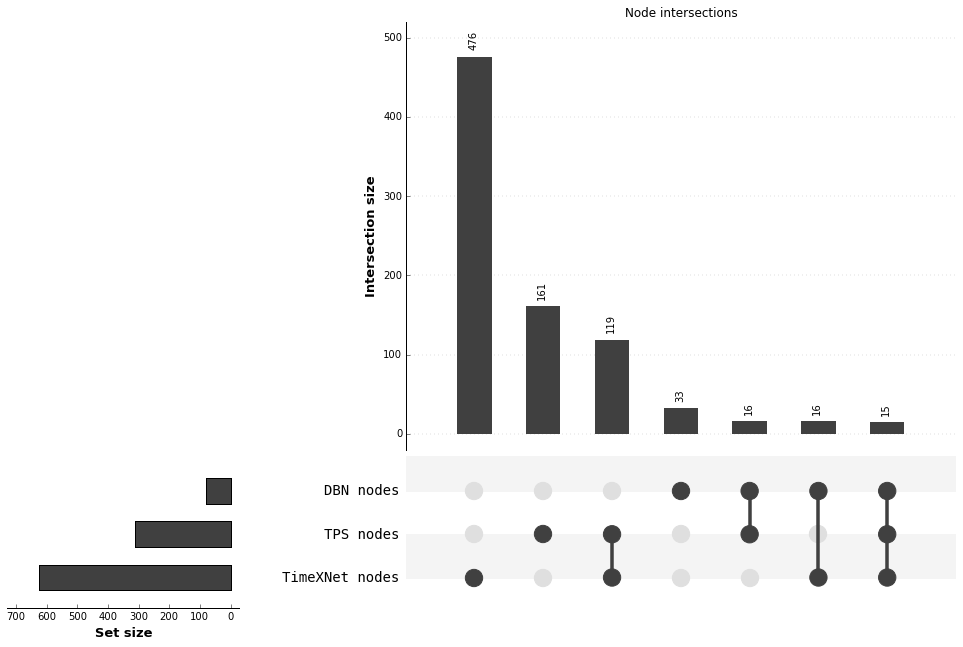

In [9]:
visualize_intersections(0.04)

Generating figures for DBN edges with probability >= 0.030000


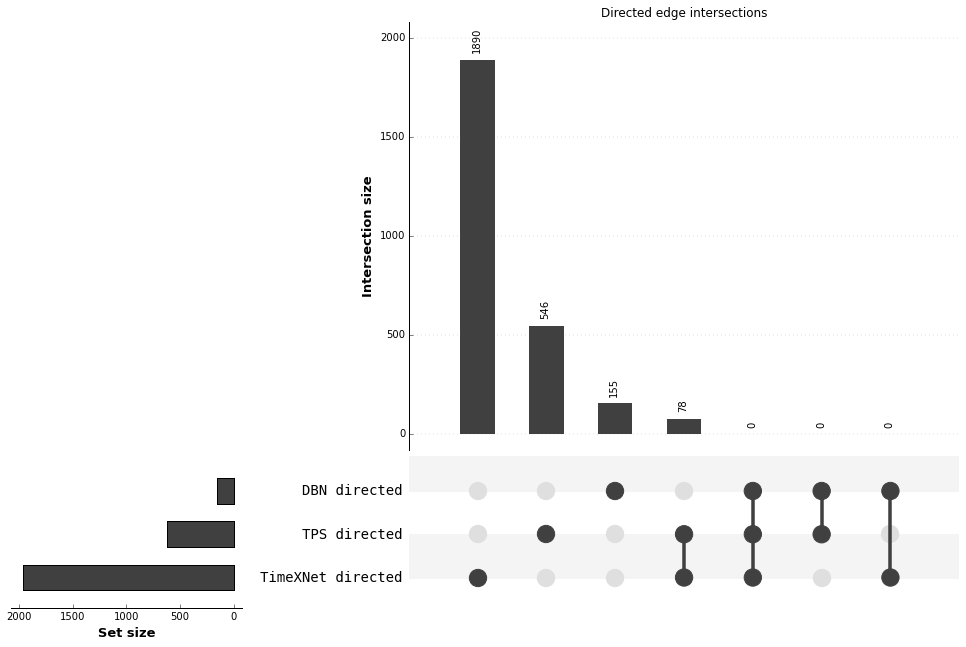

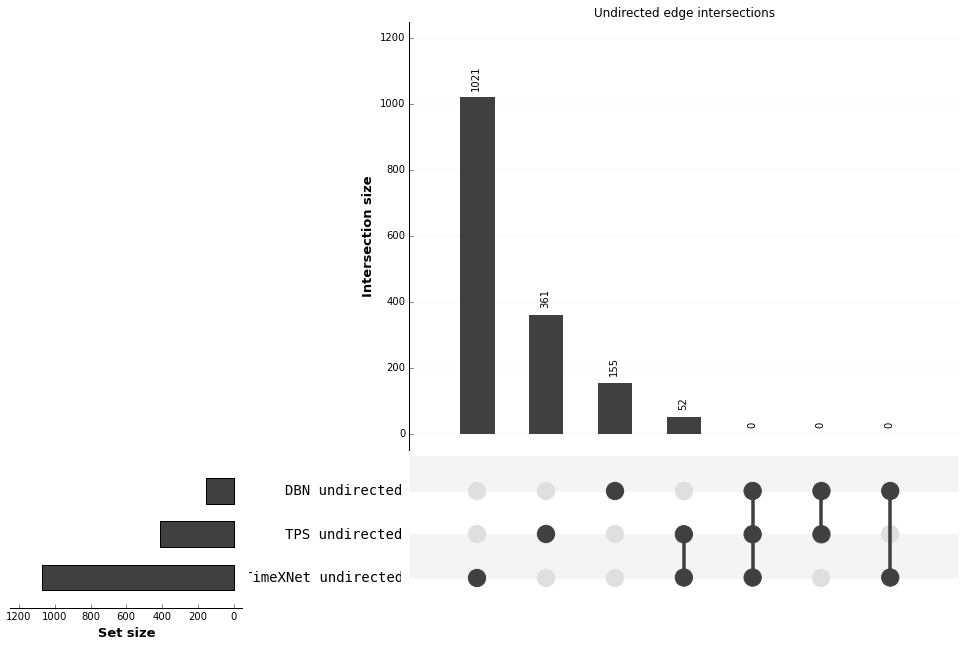

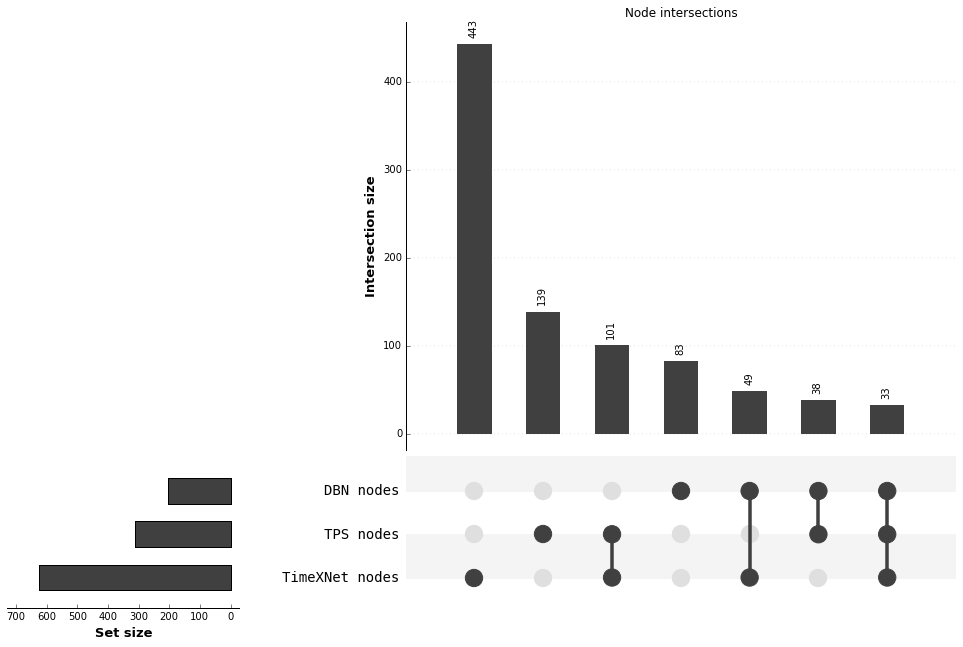

In [10]:
visualize_intersections(0.03)

Generating figures for DBN edges with probability >= 0.020000


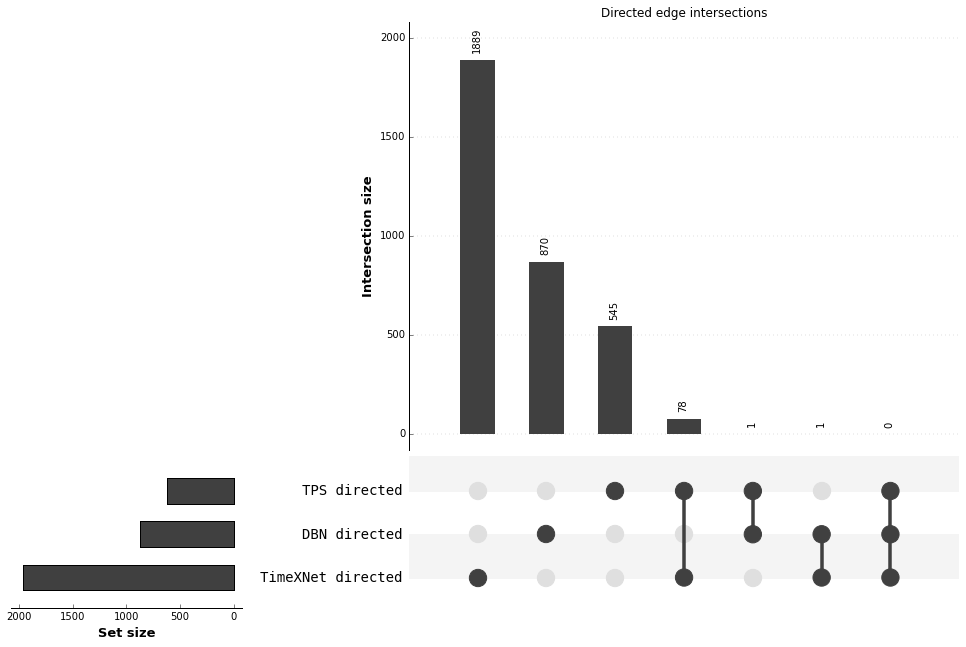

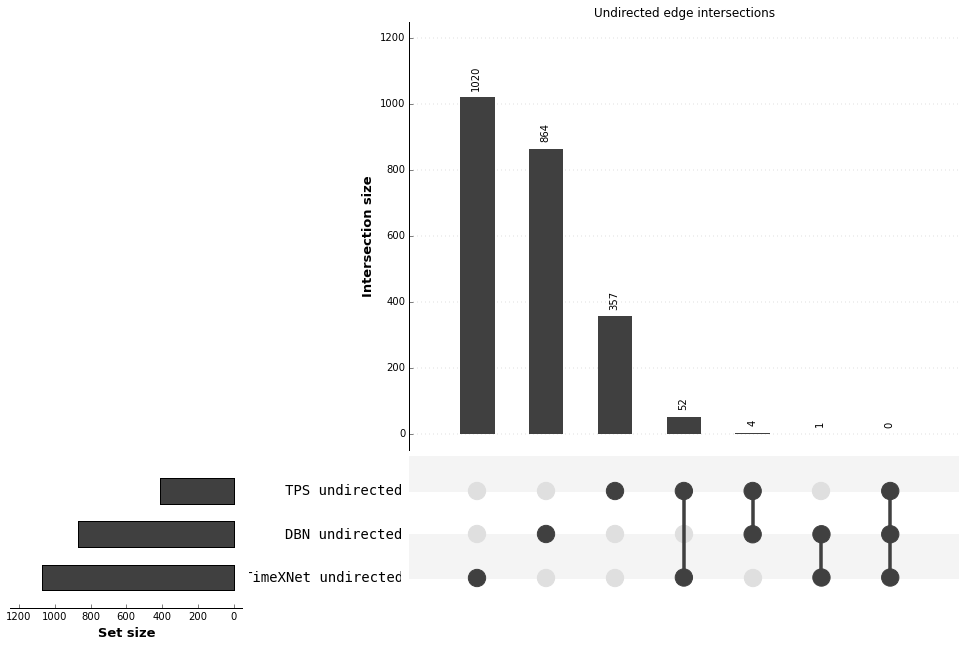

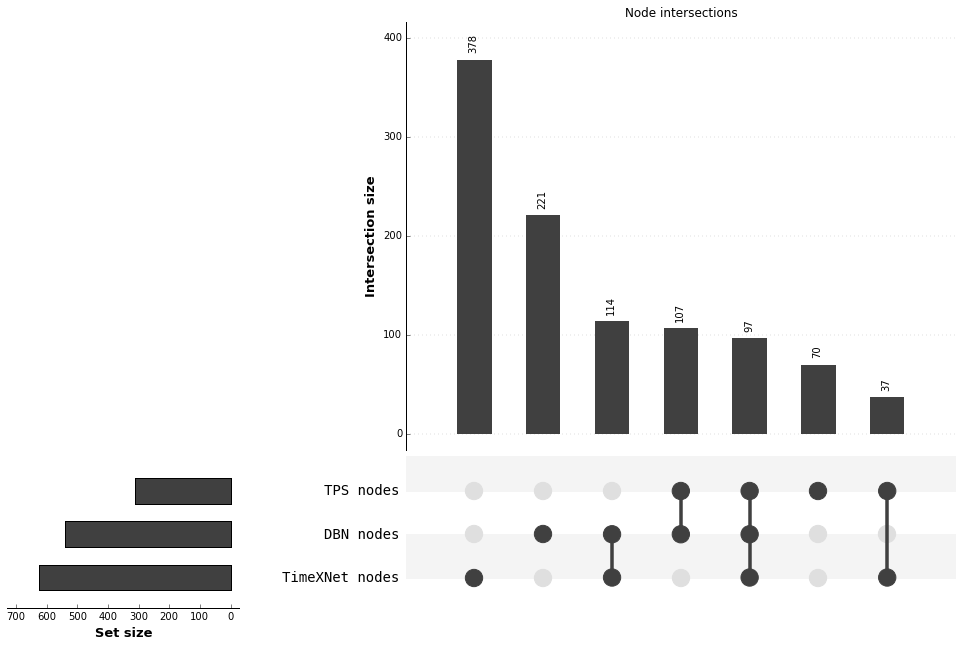

In [11]:
visualize_intersections(0.02)

Generating figures for DBN edges with probability >= 0.010000


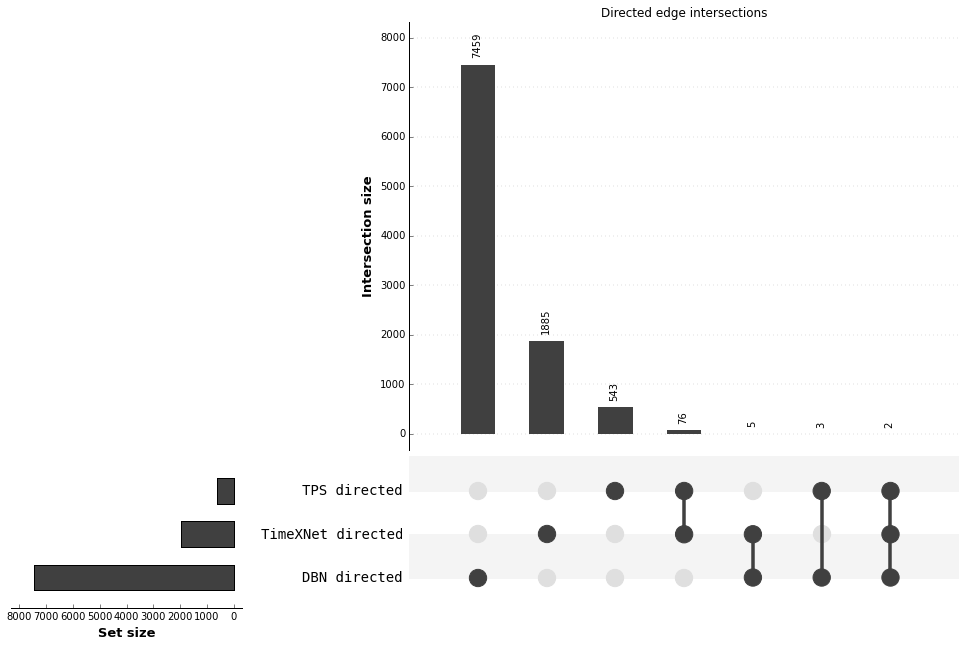

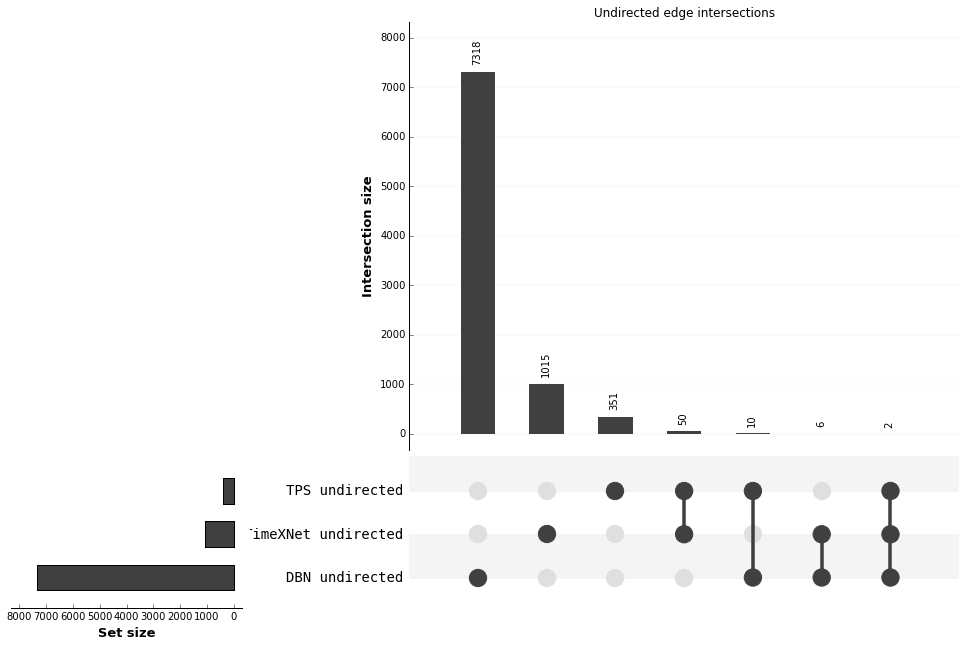

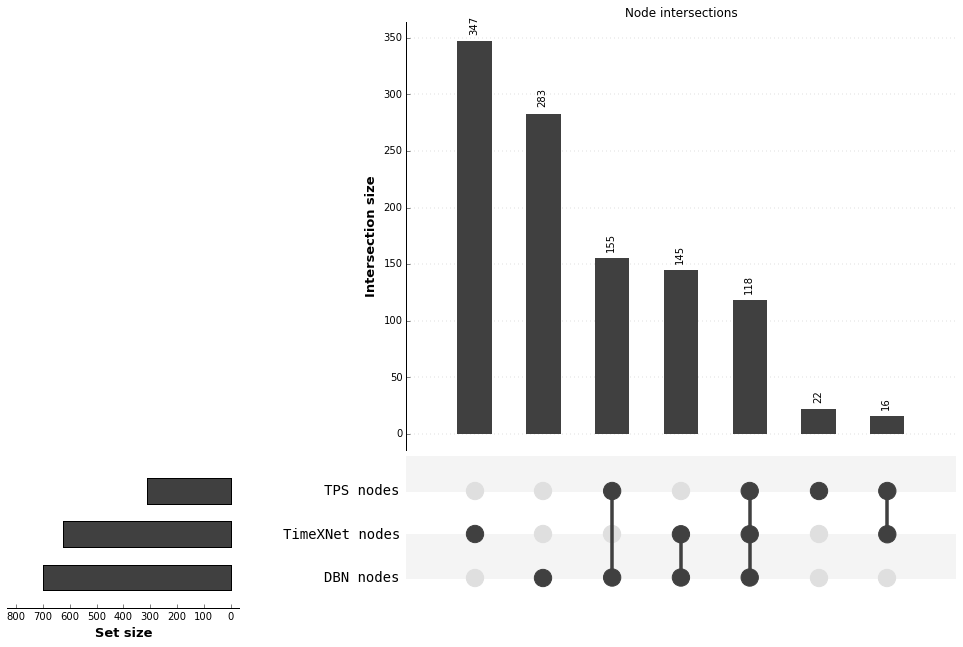

In [12]:
visualize_intersections(0.01)

DBN top 10% of peptide-peptide edges
Generating figures for DBN edges with probability >= 0.003404


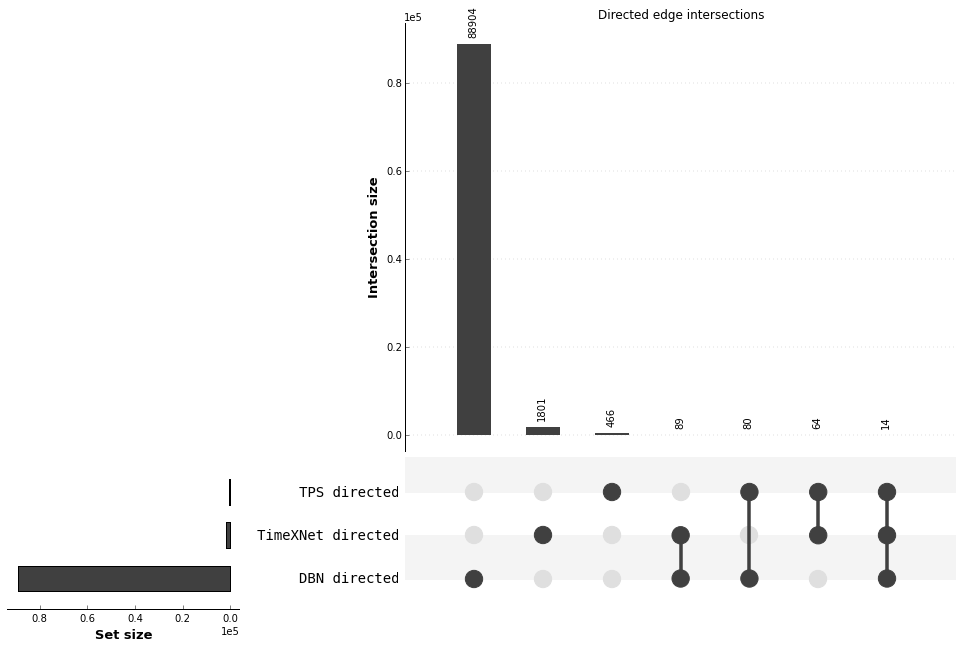

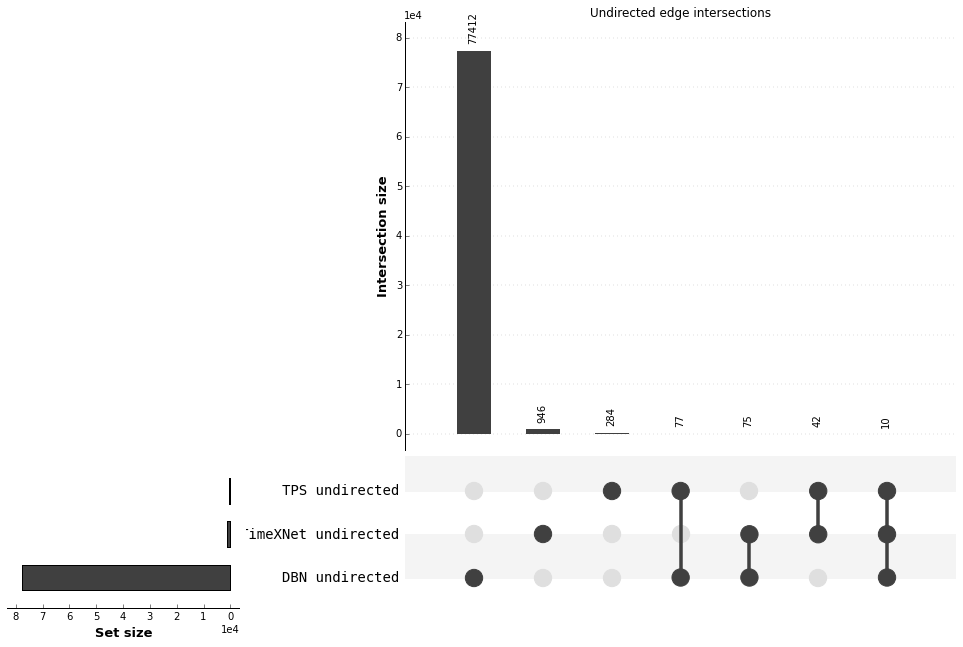

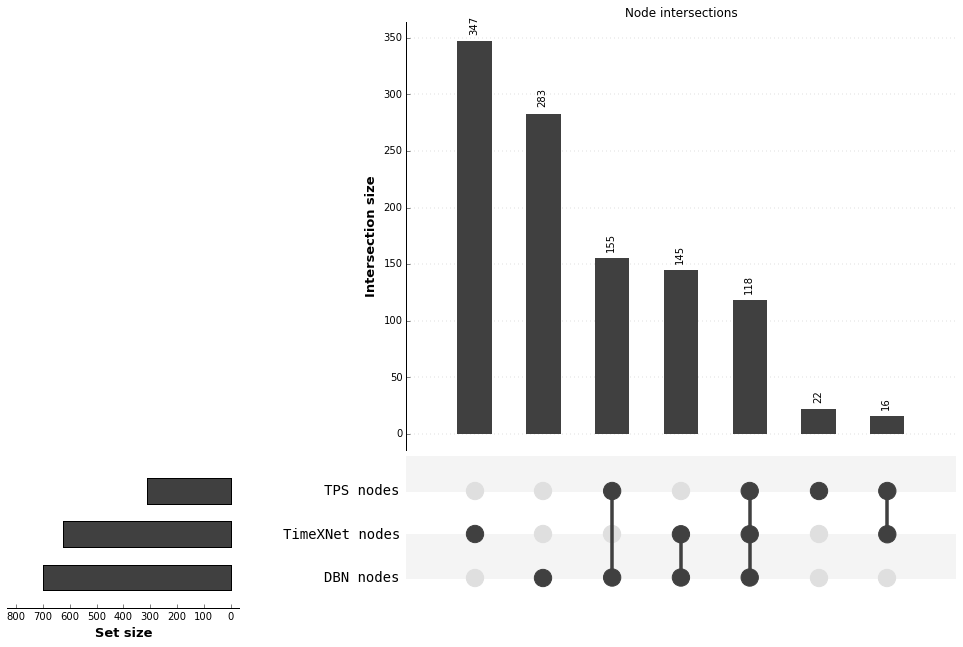

In [13]:
print 'DBN top 10% of peptide-peptide edges'
visualize_intersections(dbn_10p)

DBN top 25% of peptide-peptide edges
Generating figures for DBN edges with probability >= 0.002164


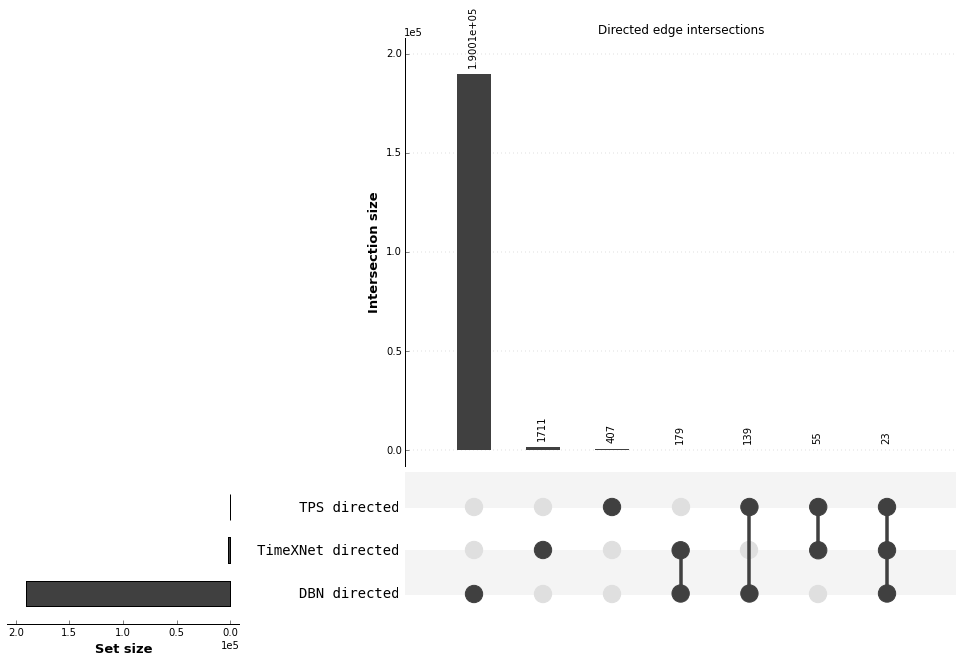

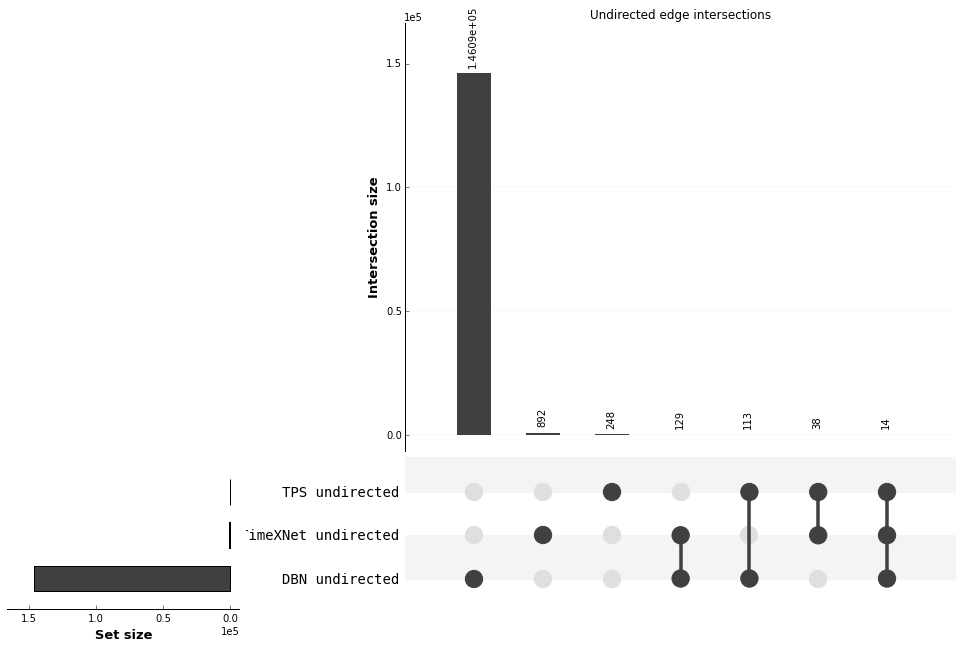

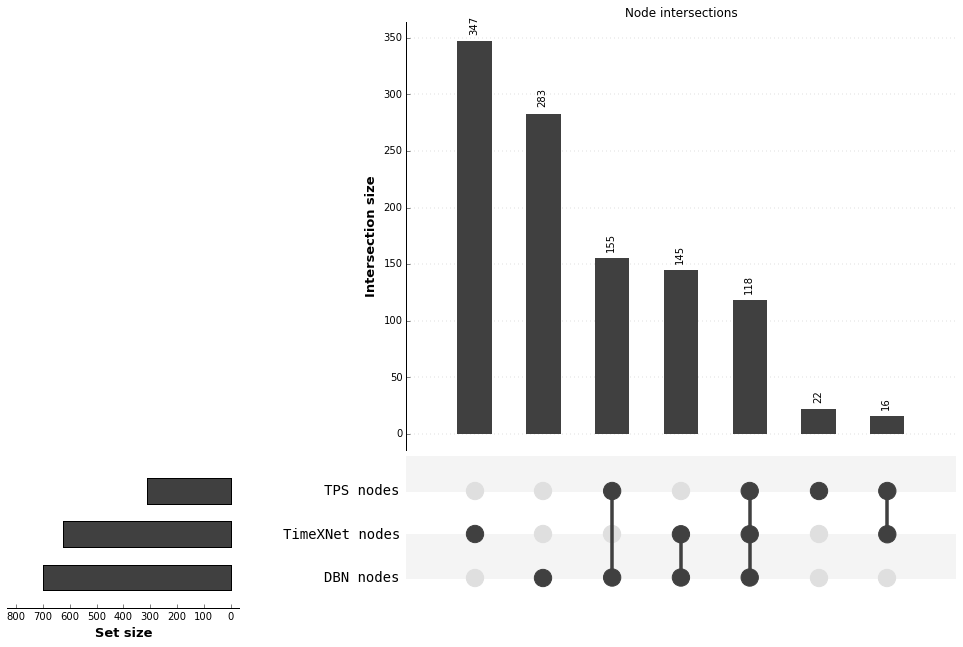

In [14]:
print 'DBN top 25% of peptide-peptide edges'
visualize_intersections(dbn_25p)